## Machine Learning aplicado a la Salud: Predicción de Presión Arterial

Diplomatura en Ciencia de Datos e Inteligencia Artificial Aplicadas a la Investigación en Salud

Prof. responsable: Lic. Stefano Staurini (stefano.staurini@unc.edu.ar)

Objetivo: Construir, optimizar y diagnosticar un modelo de regresión para predecir la Presión Arterial Sistólica.

###I. Configuración y Carga de Datos desde la Nube

Para simular un entorno de trabajo real, no crearemos los datos aquí, sino que nos conectaremos a un archivo CSV almacenado en un repositorio externo (Google Drive).

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, SGDRegressor, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
import scipy.stats as stats

# Configuración visual
sns.set_theme(style="whitegrid")

# Carga de datos desde Google Drive
FILE_ID = '1zEFAuiAKYOr6c3csOIRq4qehAnX0Z5FA'
url = f'https://drive.google.com/uc?id={FILE_ID}'

# Leemos el archivo directamente a un DataFrame de Pandas
try:
    df = pd.read_csv(url)
    print(f"Dataset cargado con éxito. Dimensiones: {df.shape[0]} filas y {df.shape[1]} columnas.")
    display(df.head())
except Exception as e:
    print(f"Error al cargar el archivo: {e}. Verifica el ID o los permisos de Drive.")

Dataset cargado con éxito. Dimensiones: 2000 filas y 10 columnas.


,Edad,IMC,Sodio_mg,Colesterol_Total,Glucosa,Horas_Sueno,Frecuencia_Cardiaca,Fumador,Nivel_Actividad,Presion_Sistolica
0,58,25.861260,1726.984806,142.660493,105.789551,7.847807,91.453550,Sí,Alto,144.4
1,71,26.936859,1710.048541,202.789377,82.350326,6.977053,72.648351,No,Medio,147.1
2,48,32.202002,2371.240977,185.945117,113.921359,6.344846,68.107234,No,Bajo,151.4
3,34,22.006584,2287.787675,177.237042,73.442783,5.380420,68.150038,No,Alto,129.5
4,62,29.937290,2465.634070,240.525570,91.328298,8.704222,69.508735,Sí,Alto,160.8


### II. Análisis Exploratorio (EDA) y Diagnóstico Estadístico

El primer paso de cualquier científico de datos es entender a sus pacientes numéricamente. Tenemos 10 variables: continuas y categóricas.

####1. Variables Numéricas: Correlación

Calculamos la matriz de correlación para buscar relaciones lineales (Pearson) o monótonas/no normales (Spearman).

Regla de oro: Buscamos variables que correlacionen alto con Presion_Sistolica (nuestra meta), pero que NO correlacionen demasiado entre sí (para evitar multicolinealidad).

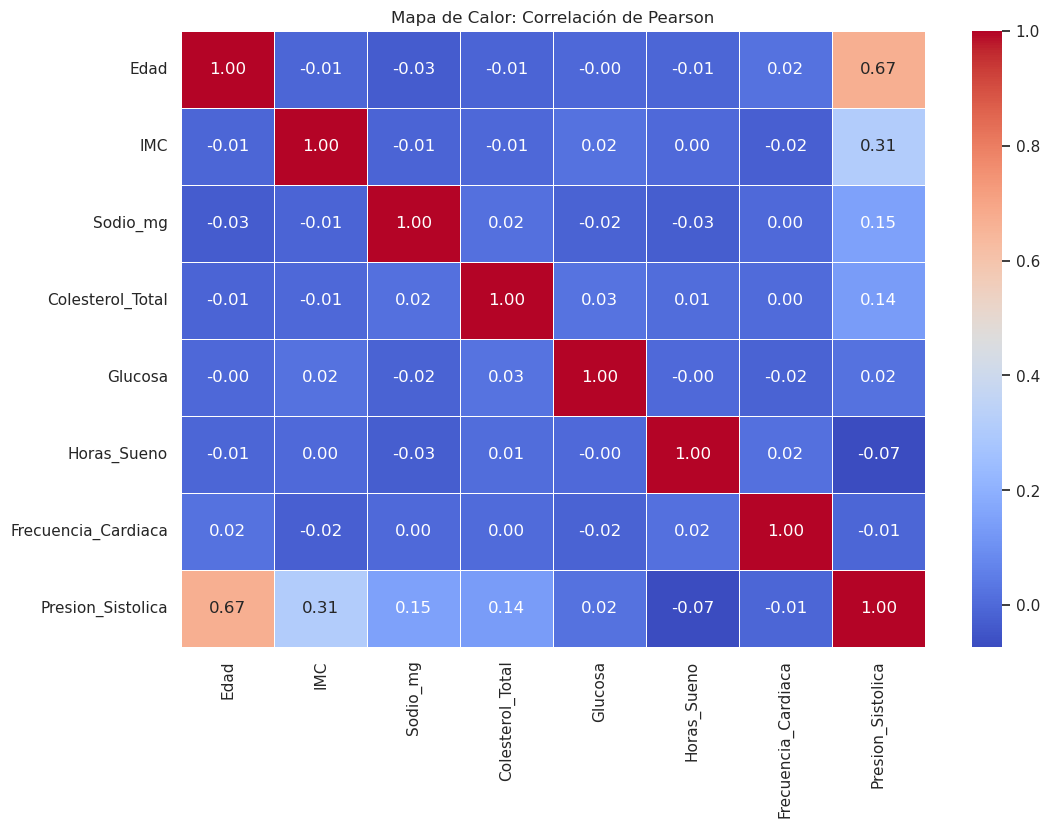

In [12]:
# Filtramos solo las variables numéricas
num_vars = df.select_dtypes(include=[np.number])

plt.figure(figsize=(12, 8))
# Usamos Pearson al asumir que la mayoría son continuas normales
sns.heatmap(num_vars.corr(method='pearson'), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Mapa de Calor: Correlación de Pearson")
plt.show()

# Nota: Si tuviéramos distribuciones muy sesgadas, cambiaríamos method='spearman'

####2. Variables Categóricas: Boxplots y Test ANOVA

¿Cómo afecta el nivel de actividad física a la presión?

El mapa de calor no nos sirve aquí. Usamos Boxplots para ver la distribución y un Test ANOVA para validar si la diferencia visual es estadísticamente significativa.

/tmp/ipykernel_51/3786990268.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Nivel_Actividad', y='Presion_Sistolica', data=df, order=['Bajo', 'Medio', 'Alto'], palette='Set2')


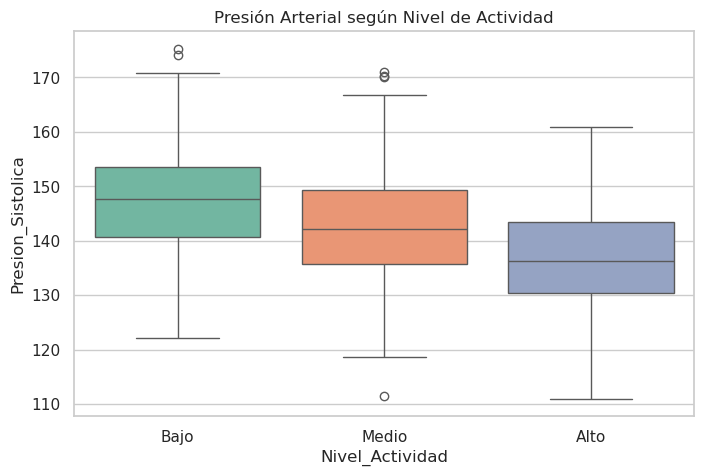

Resultado ANOVA: F=173.09, p-valor=0.00000


In [13]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Nivel_Actividad', y='Presion_Sistolica', data=df, order=['Bajo', 'Medio', 'Alto'], palette='Set2')
plt.title("Presión Arterial según Nivel de Actividad")
plt.show()

# Test ANOVA para validar la intuición del gráfico
grupos = [df[df['Nivel_Actividad'] == nivel]['Presion_Sistolica'] for nivel in ['Bajo', 'Medio', 'Alto']]
f_stat, p_val = stats.f_oneway(*grupos)
print(f"Resultado ANOVA: F={f_stat:.2f}, p-valor={p_val:.5f}")
# Un p-valor menor a 0.05 nos confirma que la Actividad SÍ impacta en la presión.

### III. Preprocesamiento

####1. Codificación (Encoding)

El algoritmo no entiende "Sí" o "Bajo". Transformamos texto en números binarios (0 y 1) mediante One-Hot Encoding.

In [14]:
df.Nivel_Actividad.value_counts()

Nivel_Actividad
Medio    816
Bajo     771
Alto     413
Name: count, dtype: int64

La función pd.get_dummies aplica una técnica llamada One-Hot Encoding. Crea columnas nuevas para cada categoría de tus variables originales.

Si la columna Fumador tiene los valores "Sí" y "No", el código creará una columna donde el "Sí" se representa con un 1 y el "No" con un 0.

In [15]:
# Convertimos categóricas a columnas binarias (ej. Fumador_Sí)
df_encoded = pd.get_dummies(df, columns=['Fumador', 'Nivel_Actividad'], drop_first=True)
display(df_encoded.head(3))

,Edad,IMC,Sodio_mg,Colesterol_Total,Glucosa,Horas_Sueno,Frecuencia_Cardiaca,Presion_Sistolica,Fumador_Sí,Nivel_Actividad_Bajo,Nivel_Actividad_Medio
0,58,25.861260,1726.984806,142.660493,105.789551,7.847807,91.453550,144.4,True,False,False
1,71,26.936859,1710.048541,202.789377,82.350326,6.977053,72.648351,147.1,False,False,True
2,48,32.202002,2371.240977,185.945117,113.921359,6.344846,68.107234,151.4,False,True,False


####2. La División de Datos (Train, Validation, Test)
Evitamos evaluar al algoritmo con los datos que usó para aprender.

In [16]:
X = df_encoded.drop('Presion_Sistolica', axis=1)   #quitando la que quieres predecir.
y = df_encoded['Presion_Sistolica']                #definiendo la que quieres predecir.

# 1. Separamos el Test definitivo (20% - "El paciente final"). Un 20% se esconde para que sirva como datos de testeo. 
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# 2. Del 80% restante, sacamos un 20% para Validación ("El simulacro de examen"). El 60% restante queda como el conjunto de entrenamiento. 
# 0.25 x 0.80 = 0.20
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42)

print(f"Entrenamiento: {len(X_train)} filas | Validación: {len(X_val)} filas | Prueba: {len(X_test)} filas")

Entrenamiento: 1200 filas | Validación: 400 filas | Prueba: 400 filas


Primero quitas el 20% para Test. Te queda el 80% del total.De ese 80%, quieres sacar un 20% (del total original) para Validación.
Matemáticamente, el 25% de 80 es 20 ($0.25 \times 0.80 = 0.20$).
Al imprimir las filas finales, verás que la suma de las tres partes da el total de tu df_encoded. Si tu modelo tiene una precisión alta en el set de Entrenamiento pero baja en el de Prueba, has caído en el Overfitting (el modelo memorizó los datos en lugar de aprender la lógica médica).

### IV. Escalado de Características (Feature Scaling)

El colesterol se mide en cientos ($200$ mg/dL) y el sueño en unidades ($7$ horas).
* Si no escalamos, el algoritmo pensará que el colesterol es "más importante" solo por ser un número más grande.
*Data Leakage: El escalador se entrena (fit) SOLO en X_train.*

* Luego se aplica (transform) a X_val y X_test. Si escalamos antes de dividir, estaríamos "espiando" los datos de prueba.

In [17]:
scaler = StandardScaler()
# Lo que hace el scaler es transformar la variables predictoras en escala Z, la cual tiene media 0 y desvios hacia - y +. De esa manera estandarizadmos el conjunto predictor
# Aprender medias y desviaciones solo del entrenamiento
X_train_scaled = scaler.fit_transform(X_train)

# Aplicar a validación y test
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Convertimos de nuevo a DataFrame solo para visualizar que todo quedó alrededor de 0
pd.DataFrame(X_train_scaled, columns=X.columns).head()

,Edad,IMC,Sodio_mg,Colesterol_Total,Glucosa,Horas_Sueno,Frecuencia_Cardiaca,Fumador_Sí,Nivel_Actividad_Bajo,Nivel_Actividad_Medio
0,1.080405,-0.836820,-1.723008,0.334894,0.730744,-0.295684,1.284959,-0.543964,1.257237,-0.825029
1,0.908511,1.048361,0.154391,1.388790,-1.743491,1.166945,-0.252531,-0.543964,-0.795395,1.212079
2,-1.498014,0.457005,-0.854775,0.298996,0.321578,0.652537,-0.061669,-0.543964,-0.795395,-0.825029
3,-0.065559,-0.278956,0.330616,0.996758,-3.137421,-1.455861,-0.013298,-0.543964,-0.795395,1.212079
4,0.736616,0.372164,-0.201586,0.308692,0.131733,1.657565,0.175772,1.838359,-0.795395,1.212079


### V. Construcción del Modelo: De Simple a Múltiple

La fórmula base de nuestro sistema:$$Y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + ... + \beta_n X_n + \epsilon$$

In [18]:
# Fase A: Modelo Simple (Pobre: solo usa la Edad)
# Usamos el formato reshape(-1, 1) porque Scikit-Learn requiere matrices 2D para las X
modelo_simple = LinearRegression().fit(X_train[['Edad']].values.reshape(-1, 1), y_train)
r2_simple = modelo_simple.score(X_val[['Edad']].values.reshape(-1, 1), y_val)

# Fase B: Modelo Múltiple (Usa todo el arsenal)
modelo_mult = LinearRegression().fit(X_train_scaled, y_train)
r2_mult = modelo_mult.score(X_val_scaled, y_val)

print(f"R² Modelo Simple (Solo Edad): {r2_simple:.4f}")
print(f"R² Modelo Múltiple (Todas las variables): {r2_mult:.4f}")

R² Modelo Simple (Solo Edad): 0.3895
R² Modelo Múltiple (Todas las variables): 0.8487


### VI. Optimización y Fine-Tuning


La optimizacion busca minimizar el termino E error, mapeando el espacio que presenta el menor error convergente. 

#### 1. OLS vs Descenso de Gradiente
OLS (Ordinary Least Squares): Encuentra la respuesta matemáticamente exacta en un solo paso. Excelente para tablas pequeñas.

Descenso de Gradiente (SGD): Aprende paso a paso. Se usa cuando los datos son gigantescos o en Redes Neuronales.

In [19]:
# OLS (Exacto)
ols = LinearRegression().fit(X_train_scaled, y_train)

# SGD (Iterativo)
sgd = SGDRegressor(max_iter=1000, learning_rate='optimal', random_state=42).fit(X_train_scaled, y_train)

print(f"Intercepto OLS: {ols.intercept_:.2f}")
print(f"Intercepto SGD: {sgd.intercept_[0]:.2f}")
# Noten que llegan casi exactamente al mismo lugar, pero por caminos distintos.

Intercepto OLS: 143.11
Intercepto SGD: 143.61


El intercepto (o constante $\beta_0$) es el valor predicho de tu variable dependiente ($y$) cuando todas las variables independientes ($X$) son iguales a cero.En tu caso: Si tuvieras un paciente con 0 años, 0 colesterol, que no fuma y no tiene obesidad, su Presión Sistólica inicial sería de 143 mmHg.
En medicina, el intercepto a veces no tiene sentido biológico (nadie tiene 0 años), pero es el "punto de partida" matemático necesario para que la línea de regresión se ubique correctamente en el gráfico.

#### 2. Fine-Tuning Automático con GridSearchCV

Vamos a usar Ridge (que incluye regularización para evitar que el modelo confíe demasiado en una sola variable) y pediremos a la computadora que pruebe cuál es la "fuerza" (Alpha) perfecta.

Aquí estás usando una Regresión Ridge, que es una versión de la regresión lineal que incluye una "penalización" (llamada Alpha) para evitar que el modelo se vuelva demasiado complejo y cometa errores de sobreajuste (overfitting). El valor de alpha no lo aprende el modelo solo; tú debes proponérselo. 
Grid Search: Prueba el modelo automáticamente con cada uno de los valores de la lista (uno por uno). Cross-Validation (cv=5): No se conforma con probarlos una vez. Divide tus datos de entrenamiento en 5 partes (folds). Entrena el modelo en 4 partes y lo prueba en la 1 restante, rotando este proceso 5 veces para cada valor de Alpha.

In [20]:
parametros = {'alpha': [0.1, 1.0, 10.0, 50.0, 100.0]}
# cv=5 significa 5-Fold Cross Validation
grid = GridSearchCV(Ridge(), parametros, cv=5, scoring='neg_mean_squared_error')
grid.fit(X_train_scaled, y_train)

mejor_modelo = grid.best_estimator_
print(f"El mejor hiperparámetro encontrado fue: {grid.best_params_}")

El mejor hiperparámetro encontrado fue: {'alpha': 1.0}


Al usar Ridge con GridSearchCV. 
Robustez: Te aseguras de que el modelo no esté "memorizando" ruidos del colesterol o la edad.
Generalización: El modelo que sale de aquí (el mejor_modelo) es el que mejor funcionará con pacientes nuevos que no están en tu base de datos.

### VII. Diagnóstico y Evaluación (El Examen Final)

Evaluamos al modelo final con X_test, el conjunto que mantuvimos bajo llave.

In [21]:
y_pred = mejor_modelo.predict(X_test_scaled)

print(f"Error Absoluto Medio (MAE): {mean_absolute_error(y_test, y_pred):.2f} mmHg")
print(f"Raíz del Error Cuadrático (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.2f} mmHg")
print(f"Puntuación R² Final: {r2_score(y_test, y_pred):.4f}")

Error Absoluto Medio (MAE): 3.46 mmHg
Raíz del Error Cuadrático (RMSE): 4.30 mmHg
Puntuación R² Final: 0.8136


Diagnóstico de Multicolinealidad (VIF)

Si dos variables miden lo mismo, los coeficientes $\beta$ se vuelven locos. Un VIF > 5 requiere atención.
Este código se utiliza para detectar un problema silencioso pero peligroso en los modelos de regresión: la Multicolinealidad.

El VIF (Factor de Inflación de la Varianza) mide cuánto se "infla" la varianza de un coeficiente debido a la correlación entre las variables independientes. En términos simples: sirve para saber si tienes variables que dicen prácticamente lo mismo.

In [22]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()
vif_data["Variable"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X_train_scaled, i) for i in range(X_train_scaled.shape[1])]
display(vif_data.sort_values(by="VIF", ascending=False))

,Variable,VIF
9,Nivel_Actividad_Medio,1.777258
8,Nivel_Actividad_Bajo,1.774111
7,Fumador_Sí,1.014825
6,Frecuencia_Cardiaca,1.014386
0,Edad,1.009659
3,Colesterol_Total,1.008053
2,Sodio_mg,1.006859
4,Glucosa,1.004079
5,Horas_Sueno,1.003632
1,IMC,1.003077


VIF = 1: No hay correlación en absoluto. Es el escenario ideal.
VIF entre 1 y 5: Correlación moderada. Generalmente es aceptable en estudios clínicos.

### VIII. Evaluación Diagnóstica: Los 3 problemas de Modelos supervisados

En la práctica clínica, un modelo útil debe equilibrar el sesgo y la varianza (**Bias-Variance Trade-off**). Mientras que la estadística tradicional a menudo se preocupa por el sesgo (subajuste), en Machine Learning el desafío principal suele ser controlar la varianza (sobreajuste) para garantizar que el diagnóstico sea fiable en la población general.

A continuación, se detalla cómo abordar los tres problemas más comunes:

#### 1. Multicolinealidad
Ocurre cuando dos o más variables predictoras están estrechamente relacionadas entre sí, lo que dificulta separar sus efectos individuales sobre la respuesta. Esto aumenta el error estándar de los coeficientes, haciendo que el modelo sea inestable y que variables importantes parezcan no ser significativas.
* **Cómo detectarla:** El método estándar es el Factor de Inflación de la Varianza (VIF). Un VIF > 5 o 10 indica un nivel problemático.
* **Cómo lidiar con ella:**
  * **Eliminar variables:** Descartar una de las variables problemáticas si la información es redundante.
  * **Combinar variables:** Fusionar predictores colineales (ej. promediándolos).
  * **Regularización:** El uso de Lasso (L1) fuerza a los coeficientes de las variables menos importantes o redundantes a ser cero, realizando selección automática.

#### 2. Underfitting (Subajuste)
Ocurre cuando el modelo es demasiado simple para captar la estructura subyacente de los datos (Sesgo alto). El modelo comete errores sistemáticos tanto en entrenamiento como en prueba. *(Nota: Nuestro primer modelo simple que solo usaba la "Edad" sufría de esto).*
* **Cómo lidiar con él:**
  * **Aumentar la complejidad:** Usar modelos con más parámetros (ej. redes neuronales o modelos no lineales).
  * **Feature Engineering:** Crear predictores más potentes (ej. incluir interacciones matemáticas).
  * **Reducir la regularización:** Disminuir las penalizaciones (como Alpha en Ridge/Lasso).
  * **Boosting:** Combinar secuencialmente modelos débiles.

#### 3. Overfitting (Sobreajuste)
Sucede cuando el modelo es demasiado complejo y "memoriza" el ruido o las fluctuaciones aleatorias del conjunto de entrenamiento en lugar de aprender el patrón real (Varianza alta). Funciona de maravilla con datos conocidos pero **falla con pacientes nuevos**.
* **Cómo lidiar con él:**
  * **Simplificar el modelo:** Pasar de una regresión polinomial a una lineal.
  * **Regularización (Ridge y Lasso):** Castigar coeficientes excesivamente grandes.
  * **Aumentar los datos:** Más ejemplos ayudan a distinguir la señal del ruido.
  * **Early Stopping:** Detener el entrenamiento iterativo a tiempo.
  * **Ensamblajes / Dropout:** Técnicas avanzadas en Random Forests y Redes Neuronales.

### 🧪 El Laboratorio del Mal: Creando Overfitting a propósito

Para entender el **Sobreajuste (Overfitting)**, vamos a forzar a que nuestro algoritmo "memorice" a los pacientes en lugar de entender la enfermedad.

¿Cómo lo haremos?
1. Usaremos `PolynomialFeatures(degree=3)`. Esto tomará nuestras 10 variables originales y las multiplicará entre sí.
ej. $Edad^2$, $Edad \times IMC$, etc., creando **cientos de variables nuevas artificiales**.

2. Le daremos al modelo **solo 50 pacientes** para aprender.
3. Al tener cientos de variables (complejidad extrema) y solo 50 pacientes (pocos datos), el algoritmo creará una ecuación matemática perfecta para esos 50 pacientes exactos (memorización), pero no servirá para nadie más.

In [23]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# 1. Aumentamos la complejidad al extremo (creamos cientos de columnas matemáticas falsas)
poly = PolynomialFeatures(degree=3)

# 2. Tomamos solo los primeros 50 pacientes del set de entrenamiento
# Aplicamos la transformación polinomial solo a ellos
X_train_poly = poly.fit_transform(X_train_scaled[:50])
y_train_poly = y_train[:50]

print(f"Pasamos de tener 10 variables a tener {X_train_poly.shape[1]} variables artificiales.")

# 3. Entrenamos el modelo con este exceso de complejidad
modelo_overfit = LinearRegression().fit(X_train_poly, y_train_poly)

# 4. EVALUACIÓN EN ENTRENAMIENTO (El modelo rinde su propio examen)
score_train = modelo_overfit.score(X_train_poly, y_train_poly)
print(f"\nScore en Entrenamiento: {score_train:.4f}")
print("¡El modelo sacó un 1.0 (100%)! Parece perfecto, pero en realidad 'memorizó' el ruido biológico de esos 50 pacientes.")

# 5. EVALUACIÓN EN VALIDACIÓN (Pacientes nuevos del mundo real)
# Primero transformamos los datos de validación al mismo formato loco de cientos de variables
X_val_poly = poly.transform(X_val_scaled)
score_val = modelo_overfit.score(X_val_poly, y_val)

print(f"\nScore en Validación: {score_val:.4f}")
print("¡Desastre total! El score colapsa (incluso puede ser negativo).")
print("Conclusión clínica: Un modelo sobreajustado es inútil y peligroso en la vida real.")

Pasamos de tener 10 variables a tener 286 variables artificiales.

Score en Entrenamiento: 1.0000
¡El modelo sacó un 1.0 (100%)! Parece perfecto, pero en realidad 'memorizó' el ruido biológico de esos 50 pacientes.

Score en Validación: 0.5836
¡Desastre total! El score colapsa (incluso puede ser negativo).
Conclusión clínica: Un modelo sobreajustado es inútil y peligroso en la vida real.


###IX. Interpretación Clínica y Puesta en Producción

¿Qué le decimos al equipo médico? Extraemos los pesos ($\beta$) de cada variable.

/tmp/ipykernel_51/776759704.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Peso (Beta)', y='Variable', data=coeficientes, palette='viridis')


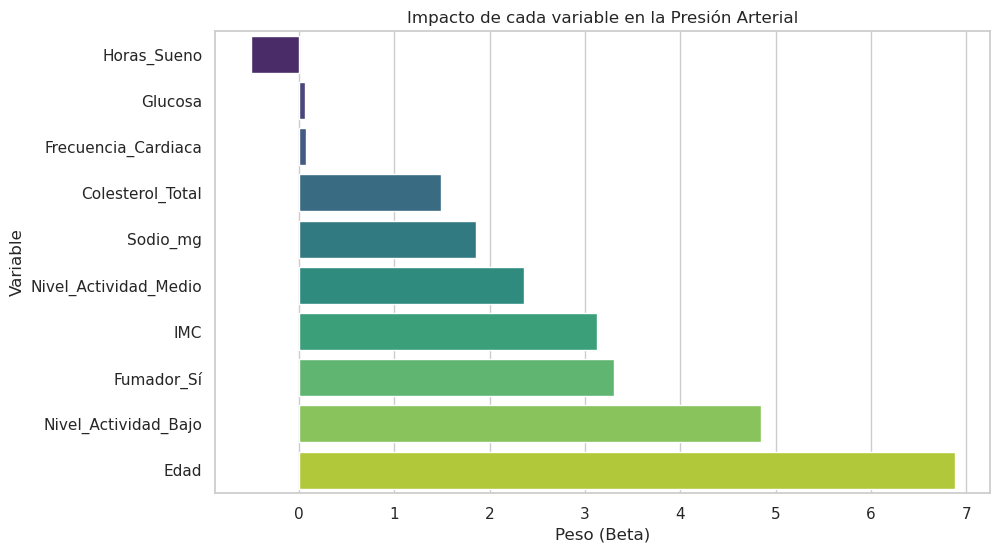

In [24]:
# Visualización de los coeficientes del mejor modelo
coeficientes = pd.DataFrame({
    'Variable': X.columns,
    'Peso (Beta)': mejor_modelo.coef_
}).sort_values(by='Peso (Beta)')

plt.figure(figsize=(10, 6))
sns.barplot(x='Peso (Beta)', y='Variable', data=coeficientes, palette='viridis')
plt.title("Impacto de cada variable en la Presión Arterial")
plt.show()

Interpretación: Las barras hacia la derecha aumentan la presión; las barras hacia la izquierda la disminuyen.

In [25]:
import joblib

# Empaquetamos el modelo y el escalador juntos para que no haya errores de formato en el futuro
joblib.dump({'modelo': mejor_modelo, 'escalador': scaler}, 'sistema_presion_v1.pkl')
print("Modelo listo y exportado a 'sistema_presion_v1.pkl'. Puede integrarse en la App del Centro.")

Modelo listo y exportado a 'sistema_presion_v1.pkl'. Puede integrarse en la App del Centro.


Fin.